In [ ]:
import pandas as pd
import numpy as np


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/DSA COURSE/Main Projecct/converted.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head()

/tmp/ipykernel_1581/717295763.py:3: DtypeWarning: Columns (17) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/drive/MyDrive/DSA COURSE/Main Projecct/converted.csv")


Dataset loaded successfully
Shape: (152400, 26)


,job_idx,date_dir,node_count,submit_time,start_time,end_time,wall_time,queue_time,run_time,node_hour_usage,...,job_mode,gpu_enabled,peak_power,mean_power,user_id,project_id,project_prefix,host_list,node_list,interconnect_exists
0,1,2024-01-17,60,2024-01-15 13:23:57+00:00,2024-01-17 03:33:50+00:00,2024-01-17 05:02:27+00:00,105,137393.0,5317,88.617,...,batch,NaN,100269.0,96672.0,user0001,OHF001,OHF,['frontier02047' 'frontier02144' 'frontier0216...,['x2103c7s7b0n0' 'x2104c5s7b1n0' 'x2104c7s0b1n...,False
1,2,2024-01-17,16,2024-01-17 04:39:48+00:00,2024-01-17 04:40:18+00:00,2024-01-17 05:05:24+00:00,30,30.0,1506,6.693,...,batch,NaN,23969.0,14410.0,user0002,AIU001,AIU,['frontier00099' 'frontier00232' 'frontier0036...,['x2000c6s1b0n0' 'x2001c6s3b1n0' 'x2002c6s3b1n...,False
2,3,2024-01-17,12,2024-01-17 04:04:02+00:00,2024-01-17 04:09:35+00:00,2024-01-17 05:06:39+00:00,60,333.0,3424,11.413,...,batch,NaN,25241.0,14426.0,user0003,TYO001,TYO,['frontier07720' 'frontier07721' 'frontier0772...,['x2501c2s3b1n0' 'x2501c2s4b0n0' 'x2501c2s4b1n...,False
3,4,2024-01-17,2,2024-01-17 03:09:54+00:00,2024-01-17 03:10:18+00:00,2024-01-17 05:10:19+00:00,120,24.0,7201,4.001,...,batch,NaN,1642.0,1602.0,user0004,VNY001,VNY,['frontier04712' 'frontier04713'],['x2300c6s3b1n0' 'x2300c6s4b0n0'],False
4,5,2024-01-17,2048,2024-01-17 00:08:01+00:00,2024-01-17 04:58:24+00:00,2024-01-17 05:16:56+00:00,25,17423.0,1112,632.604,...,batch,NaN,2719996.0,2397333.0,user0005,OHF001,OHF,['frontier00047' 'frontier00048' 'frontier0004...,['x2000c2s7b0n0' 'x2000c2s7b1n0' 'x2000c3s0b0n...,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152400 entries, 0 to 152399
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   job_idx              152400 non-null  int64  
 1   date_dir             152400 non-null  object 
 2   node_count           152400 non-null  int64  
 3   submit_time          152400 non-null  object 
 4   start_time           152400 non-null  object 
 5   end_time             152400 non-null  object 
 6   wall_time            152400 non-null  int64  
 7   queue_time           152399 non-null  float64
 8   run_time             152400 non-null  int64  
 9   node_hour_usage      152400 non-null  float64
 10  completion_state     152400 non-null  object 
 11  exit_code            152400 non-null  object 
 12  derived_exit_code    152400 non-null  object 
 13  init_priority        151396 non-null  float64
 14  final_priority       152400 non-null  int64  
 15  queue            

In [ ]:
# Check dataset structure
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False))

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (152400, 26)

Column Names:
['job_idx', 'date_dir', 'node_count', 'submit_time', 'start_time', 'end_time', 'wall_time', 'queue_time', 'run_time', 'node_hour_usage', 'completion_state', 'exit_code', 'derived_exit_code', 'init_priority', 'final_priority', 'queue', 'job_mode', 'gpu_enabled', 'peak_power', 'mean_power', 'user_id', 'project_id', 'project_prefix', 'host_list', 'node_list', 'interconnect_exists']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152400 entries, 0 to 152399
Data columns (total 26 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   job_idx              152400 non-null  int64  
 1   date_dir             152400 non-null  object 
 2   node_count           152400 non-null  int64  
 3   submit_time          152400 non-null  object 
 4   start_time           152400 non-null  object 
 5   end_time             152400 non-null  object 
 6   wall_time            152400 n

In [ ]:
# Numerical feature analysis
numeric_cols = [
    "node_count",
    "wall_time",
    "queue_time",
    "run_time",
    "node_hour_usage",
    "peak_power",
    "mean_power"
]

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
node_count,152400.0,124.716017,6.364758e+02,1.000,1.000,4.000,21.000,9.450000e+03
wall_time,152400.0,99.568504,1.320269e+02,1.000,30.000,119.000,120.000,1.440000e+03
queue_time,152399.0,25168.391558,1.164749e+05,0.000,41.000,1055.000,11391.000,1.033047e+07
run_time,152400.0,4022.559298,6.115908e+03,70.000,682.000,2764.000,6500.000,8.642900e+04
node_hour_usage,152400.0,135.909460,1.196102e+03,0.039,0.667,2.006,16.018,7.524348e+04
peak_power,152400.0,167430.649219,1.024442e+06,309.000,1285.000,5079.500,30916.750,2.769863e+07
mean_power,152400.0,114893.553780,6.288677e+05,301.000,1085.000,3702.000,24590.750,2.201389e+07


In [ ]:
# Sample records
display(
    df[
        [
            "submit_time",
            "start_time",
            "end_time",
            "wall_time",
            "run_time",
            "node_count",
            "mean_power",
            "peak_power"
        ]
    ].sample(10, random_state=42)
)

,submit_time,start_time,end_time,wall_time,run_time,node_count,mean_power,peak_power
68956,2024-11-18 03:17:49+00:00,2024-11-22 22:44:43+00:00,2024-11-23 00:44:46+00:00,120,7203,8,6569.0,6931.0
119474,2025-07-13 02:11:34+00:00,2025-07-13 11:44:50+00:00,2025-07-13 12:05:03+00:00,120,1213,1,548.0,612.0
70950,2024-12-06 17:47:23+00:00,2024-12-06 17:48:14+00:00,2024-12-06 17:58:38+00:00,10,624,1,882.0,911.0
80892,2025-01-29 03:05:02+00:00,2025-01-29 03:05:41+00:00,2025-01-29 03:10:31+00:00,5,290,1,556.0,640.0
151054,2025-12-31 02:05:14+00:00,2025-12-31 02:05:55+00:00,2025-12-31 02:29:52+00:00,120,1437,3,2820.0,4080.0
55532,2024-09-13 01:42:23+00:00,2024-09-13 01:42:54+00:00,2024-09-13 02:12:50+00:00,119,1796,1,2029.0,2423.0
119166,2025-07-09 16:19:42+00:00,2025-07-10 02:05:41+00:00,2025-07-10 03:35:56+00:00,90,5415,1,845.0,1378.0
39257,2024-06-12 02:44:10+00:00,2024-06-12 16:06:45+00:00,2024-06-12 18:06:49+00:00,120,7204,1,652.0,684.0
140166,2025-11-04 20:39:52+00:00,2025-11-05 02:22:37+00:00,2025-11-05 02:52:41+00:00,30,1804,4,6586.0,7508.0
67935,2024-11-22 06:36:09+00:00,2024-11-22 06:37:04+00:00,2024-11-22 06:41:32+00:00,120,268,64,59267.0,147150.0


In [ ]:
# Create electricity consumption target

df["energy_kwh"] = (
    df["mean_power"] * df["run_time"]
) / 3_600_000

# Display the new target
display(
    df[
        ["mean_power", "run_time", "energy_kwh"]
    ].head(10)
)

,mean_power,run_time,energy_kwh
0,96672.0,5317,142.779173
1,14410.0,1506,6.028183
2,14426.0,3424,13.720729
3,1602.0,7201,3.204445
4,2397333.0,1112,740.509527
5,41803.0,4081,47.388345
6,1543.0,180,0.077150
7,7486.0,6538,13.595408
8,668.0,220,0.040822
9,1604.0,519,0.231243


In [ ]:
# Check target quality

print("Missing energy values:",
      df["energy_kwh"].isna().sum())

print("Infinite energy values:",
      (~df["energy_kwh"].map(
          lambda x: abs(x) != float("inf")
      )).sum())

print("Zero or negative energy values:",
      (df["energy_kwh"] <= 0).sum())

print("\nEnergy consumption statistics:")
display(df["energy_kwh"].describe())

Missing energy values: 0
Infinite energy values: 0
Zero or negative energy values: 0

Energy consumption statistics:


,energy_kwh
count,152400.000000
mean,141.414464
std,1314.338755
min,0.018600
25%,0.498752
50%,2.900410
75%,16.794892
max,105005.043000


In [ ]:
df["energy_kwh"].describe()

,energy_kwh
count,152400.000000
mean,141.414464
std,1314.338755
min,0.018600
25%,0.498752
50%,2.900410
75%,16.794892
max,105005.043000


In [ ]:
# Convert submit_time to datetime if it isn't already
df["submit_time"] = pd.to_datetime(df["submit_time"])

# Engineer the missing datetime features
df["submit_hour"] = df["submit_time"].dt.hour
df["submit_dayofweek"] = df["submit_time"].dt.dayofweek
df["submit_month"] = df["submit_time"].dt.month
df["is_weekend"] = df["submit_dayofweek"].isin([5, 6]).astype(int)

# Cyclical features for hour
df["hour_sin"] = np.sin(2 * np.pi * df["submit_hour"] / 24.0)
df["hour_cos"] = np.cos(2 * np.pi * df["submit_hour"] / 24.0)

# Define input features
feature_columns = [
    "node_count",
    "wall_time",
    "queue",
    "job_mode",
    "gpu_enabled",
    "interconnect_exists",
    "submit_hour",
    "submit_dayofweek",
    "submit_month",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

# Create model dataset
X = df[feature_columns].copy()
y = df["energy_kwh"].copy()

# Handle GPU missing values
X["gpu_enabled"] = (
    X["gpu_enabled"]
    .fillna("Unknown")
    .astype(str)
)

# Verify
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
display(X.head())

print("\nTarget:")
display(y.head())

Features shape: (152400, 12)
Target shape: (152400,)

Features:


,node_count,wall_time,queue,job_mode,gpu_enabled,interconnect_exists,submit_hour,submit_dayofweek,submit_month,is_weekend,hour_sin,hour_cos
0,60,105,batch-normal,batch,Unknown,False,13,0,1,0,-0.258819,-0.965926
1,16,30,batch-normal,batch,Unknown,False,4,2,1,0,0.866025,0.500000
2,12,60,batch-normal,batch,Unknown,False,4,2,1,0,0.866025,0.500000
3,2,120,batch-normal,batch,Unknown,False,3,2,1,0,0.707107,0.707107
4,2048,25,batch-normal,batch,Unknown,False,0,2,1,0,0.000000,1.000000



Target:


,energy_kwh
0,142.779173
1,6.028183
2,13.720729
3,3.204445
4,740.509527


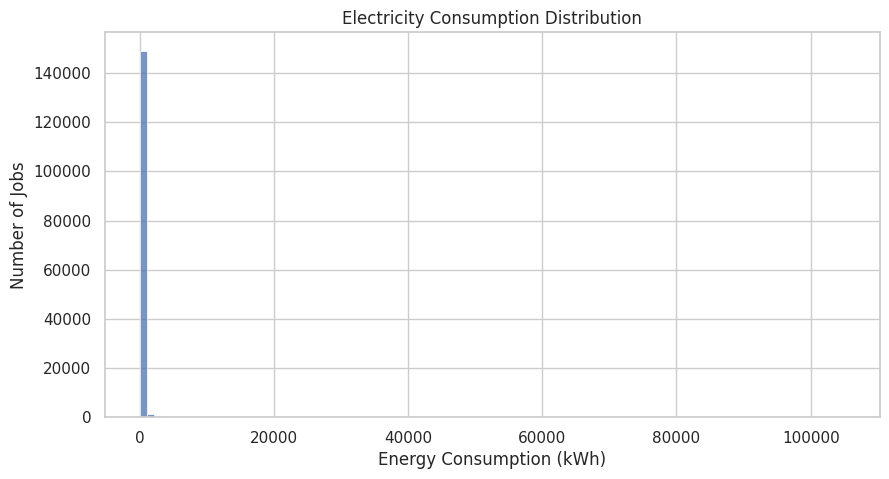

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="energy_kwh",
    bins=100
)

plt.title("Electricity Consumption Distribution")
plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of Jobs")

plt.show()

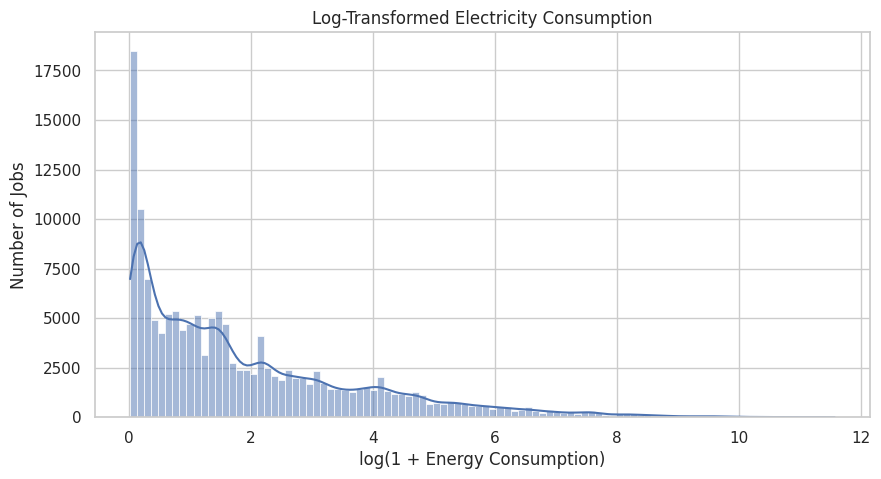

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df["energy_kwh"]),
    bins=100,
    kde=True
)

plt.title("Log-Transformed Electricity Consumption")
plt.xlabel("log(1 + Energy Consumption)")
plt.ylabel("Number of Jobs")

plt.show()

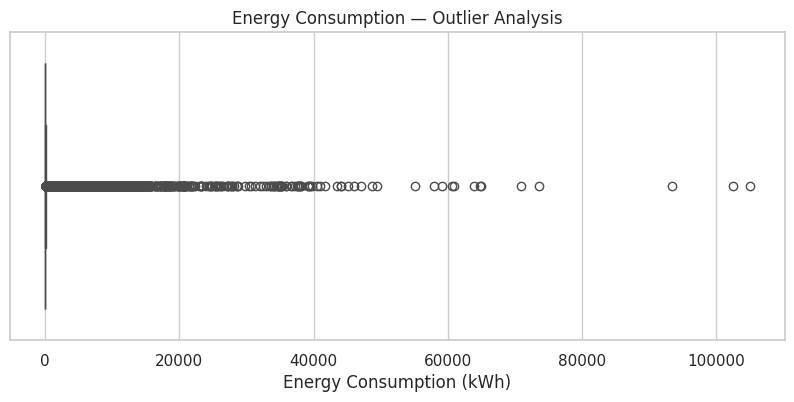

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["energy_kwh"]
)

plt.title("Energy Consumption — Outlier Analysis")
plt.xlabel("Energy Consumption (kWh)")

plt.show()

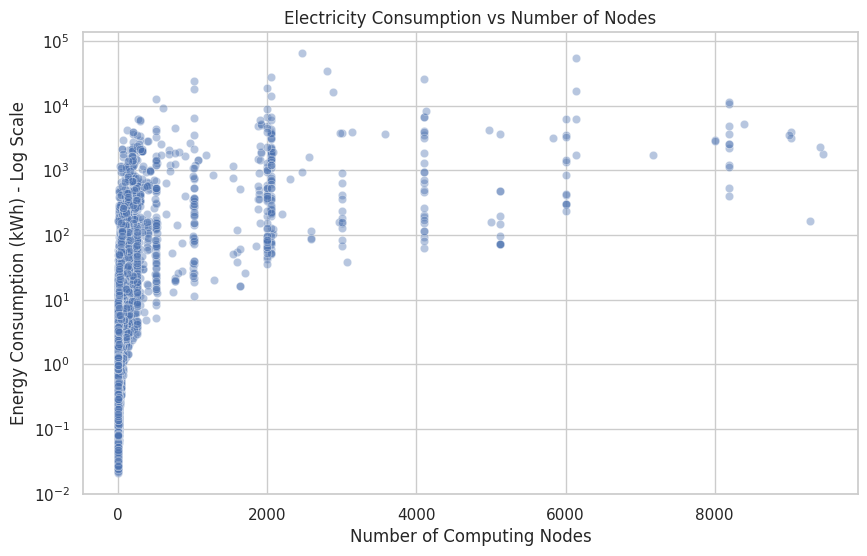

In [ ]:
# Sample records for visualization
plot_df = df.sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="node_count",
    y="energy_kwh",
    alpha=0.4
)

plt.yscale("log")

plt.title("Electricity Consumption vs Number of Nodes")
plt.xlabel("Number of Computing Nodes")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

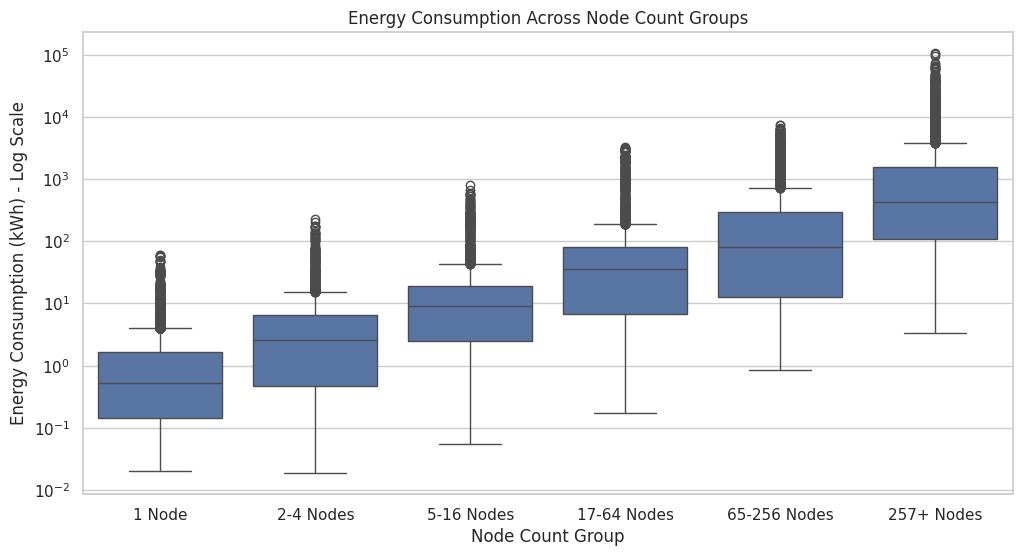

In [ ]:
# Create node-count groups
df["node_group"] = pd.cut(
    df["node_count"],
    bins=[0, 1, 4, 16, 64, 256, float("inf")],
    labels=[
        "1 Node",
        "2-4 Nodes",
        "5-16 Nodes",
        "17-64 Nodes",
        "65-256 Nodes",
        "257+ Nodes"
    ]
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="node_group",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Energy Consumption Across Node Count Groups")
plt.xlabel("Node Count Group")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

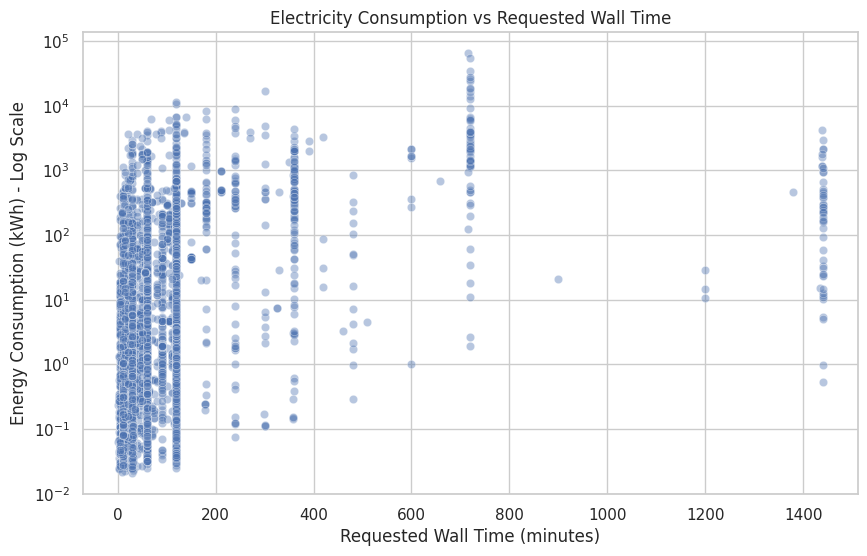

In [ ]:
# Sample for visualization
plot_df = df.sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="wall_time",
    y="energy_kwh",
    alpha=0.4
)

plt.yscale("log")

plt.title("Electricity Consumption vs Requested Wall Time")
plt.xlabel("Requested Wall Time (minutes)")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

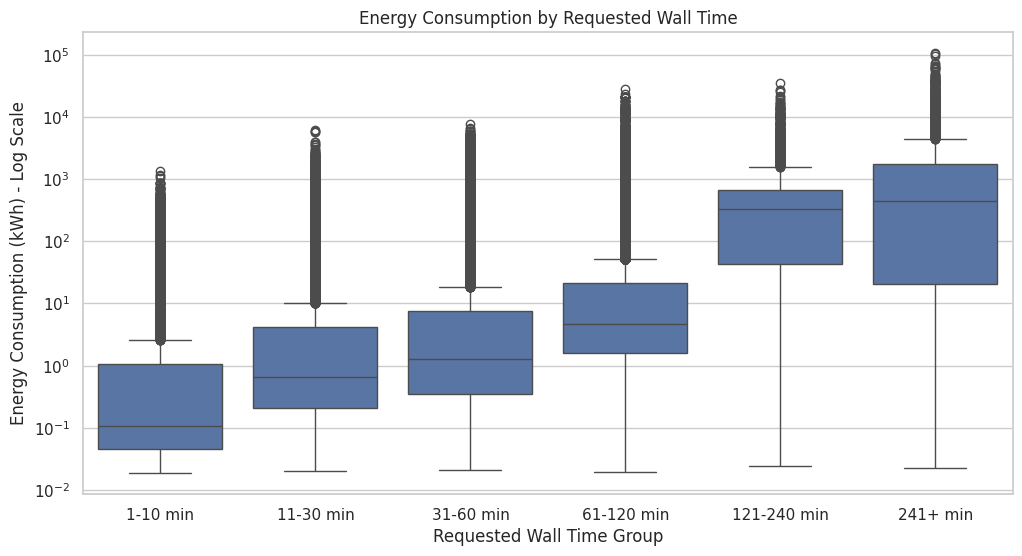

In [ ]:
# Create wall-time groups
df["wall_time_group"] = pd.cut(
    df["wall_time"],
    bins=[0, 10, 30, 60, 120, 240, 1440],
    labels=[
        "1-10 min",
        "11-30 min",
        "31-60 min",
        "61-120 min",
        "121-240 min",
        "241+ min"
    ],
    include_lowest=True
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="wall_time_group",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Energy Consumption by Requested Wall Time")
plt.xlabel("Requested Wall Time Group")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

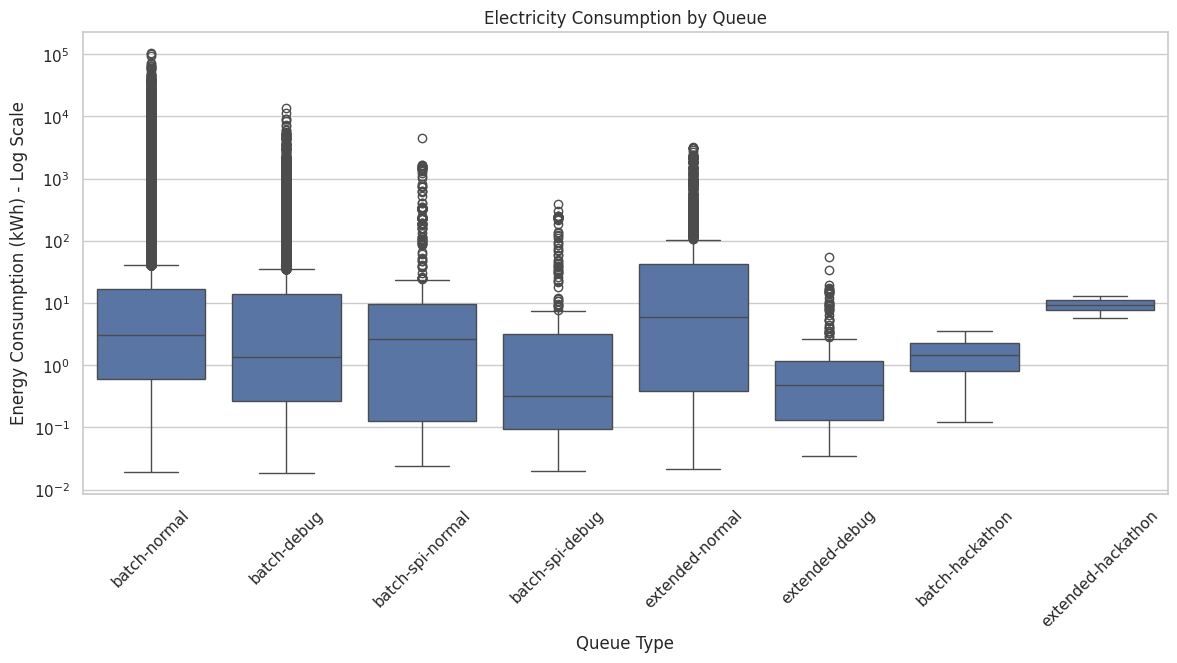

In [ ]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="queue",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Electricity Consumption by Queue")
plt.xlabel("Queue Type")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.xticks(rotation=45)

plt.show()

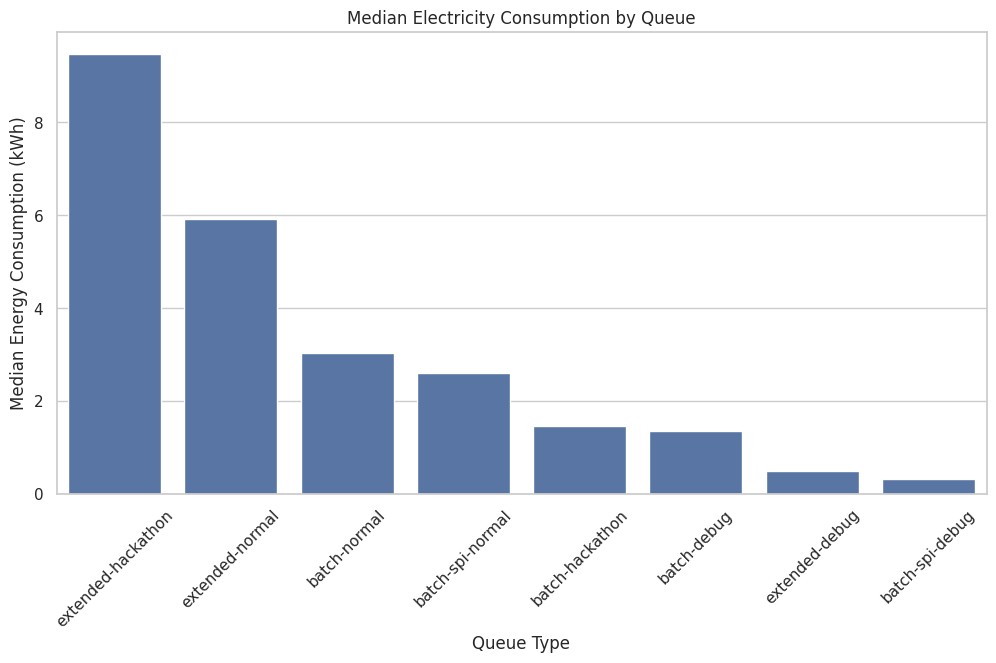

In [ ]:
queue_energy = (
    df.groupby("queue", observed=True)["energy_kwh"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=queue_energy.index,
    y=queue_energy.values
)

plt.title("Median Electricity Consumption by Queue")
plt.xlabel("Queue Type")
plt.ylabel("Median Energy Consumption (kWh)")

plt.xticks(rotation=45)

plt.show()

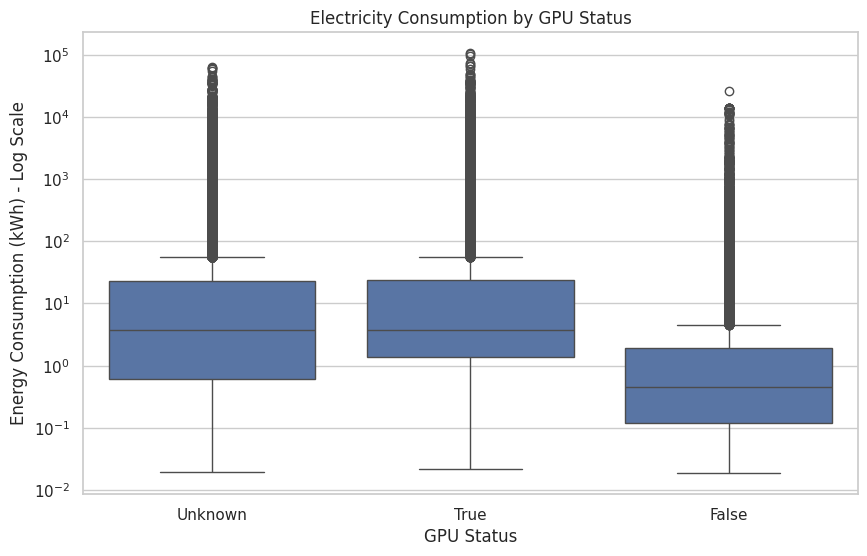

In [ ]:
# Create a visualization-only GPU status column
gpu_plot_df = df.copy()

gpu_plot_df["gpu_status"] = (
    gpu_plot_df["gpu_enabled"]
    .fillna("Unknown")
    .astype(str)
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=gpu_plot_df,
    x="gpu_status",
    y="energy_kwh"
)

plt.yscale("log")

plt.title("Electricity Consumption by GPU Status")
plt.xlabel("GPU Status")
plt.ylabel("Energy Consumption (kWh) - Log Scale")

plt.show()

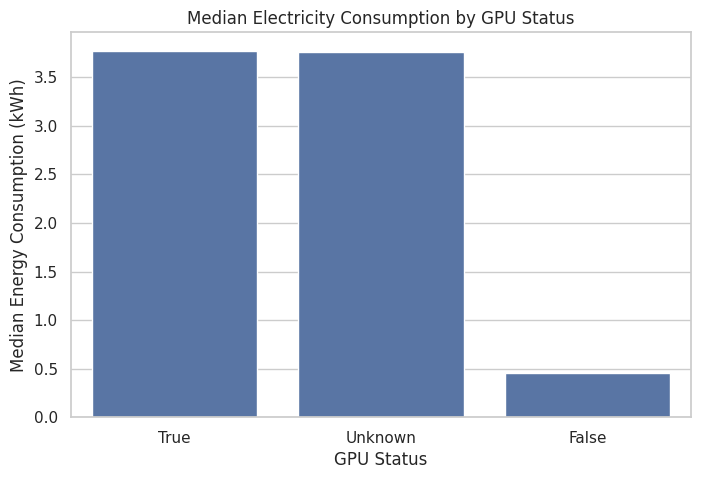

In [ ]:
gpu_median_energy = (
    gpu_plot_df.groupby("gpu_status")["energy_kwh"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=gpu_median_energy.index,
    y=gpu_median_energy.values
)

plt.title("Median Electricity Consumption by GPU Status")
plt.xlabel("GPU Status")
plt.ylabel("Median Energy Consumption (kWh)")

plt.show()

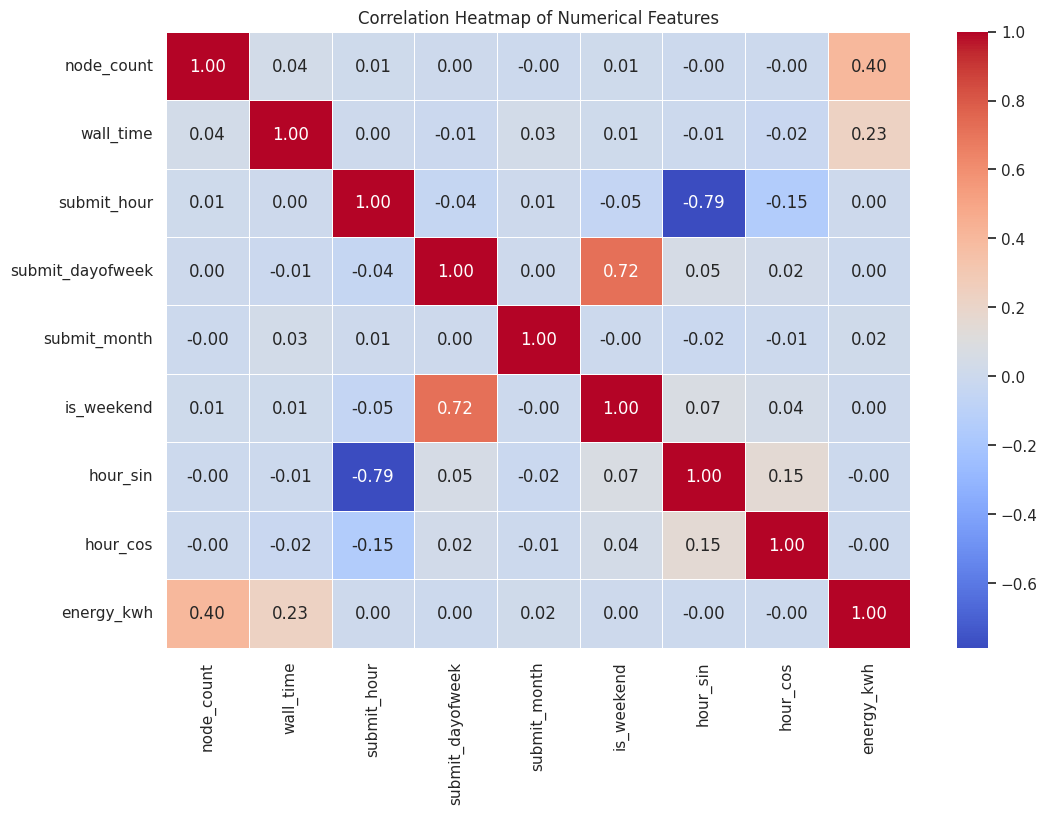

In [ ]:
# Select numerical features
numeric_features = [
    "node_count",
    "wall_time",
    "submit_hour",
    "submit_dayofweek",
    "submit_month",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "energy_kwh"
]

# Calculate correlation matrix
correlation_matrix = df[numeric_features].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

In [ ]:
# Get correlation with energy consumption
energy_correlation = correlation_matrix["energy_kwh"]

# Sort correlations from highest to lowest
energy_correlation = energy_correlation.sort_values(
    ascending=False
)

print("Correlation with Electricity Consumption:\n")
print(energy_correlation)

Correlation with Electricity Consumption:

energy_kwh          1.000000
node_count          0.402416
wall_time           0.230443
submit_month        0.017402
submit_hour         0.004935
is_weekend          0.004072
submit_dayofweek    0.000418
hour_cos           -0.003358
hour_sin           -0.003976
Name: energy_kwh, dtype: float64


In [ ]:
def interpret_correlation(value):
    if value == 1:
        return "Perfect Positive Correlation"
    elif value >= 0.7:
        return "Strong Positive Correlation"
    elif value >= 0.3:
        return "Moderate Positive Correlation"
    elif value > 0:
        return "Weak Positive Correlation"
    elif value <= -0.7:
        return "Strong Negative Correlation"
    elif value <= -0.3:
        return "Moderate Negative Correlation"
    elif value < 0:
        return "Weak Negative Correlation"
    else:
        return "No Linear Correlation"


correlation_analysis = pd.DataFrame({
    "Correlation": energy_correlation,
    "Interpretation": energy_correlation.apply(
        interpret_correlation
    )
})

print(correlation_analysis)

                  Correlation                 Interpretation
energy_kwh           1.000000   Perfect Positive Correlation
node_count           0.402416  Moderate Positive Correlation
wall_time            0.230443      Weak Positive Correlation
submit_month         0.017402      Weak Positive Correlation
submit_hour          0.004935      Weak Positive Correlation
is_weekend           0.004072      Weak Positive Correlation
submit_dayofweek     0.000418      Weak Positive Correlation
hour_cos            -0.003358      Weak Negative Correlation
hour_sin            -0.003976      Weak Negative Correlation


In [ ]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

print("\nTarget missing values:")
print(y.isnull().sum())

Features shape: (152400, 12)
Target shape: (152400,)

Feature columns:
['node_count', 'wall_time', 'queue', 'job_mode', 'gpu_enabled', 'interconnect_exists', 'submit_hour', 'submit_dayofweek', 'submit_month', 'is_weekend', 'hour_sin', 'hour_cos']

Missing values:
node_count             0
wall_time              0
queue                  0
job_mode               0
gpu_enabled            0
interconnect_exists    0
submit_hour            0
submit_dayofweek       0
submit_month           0
is_weekend             0
hour_sin               0
hour_cos               0
dtype: int64

Target missing values:
0


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (121920, 12)
Testing Features: (30480, 12)
Training Target: (121920,)
Testing Target: (30480,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

categorical_features = [
    "queue",
    "job_mode",
    "gpu_enabled"
]

numerical_features = [
    "node_count",
    "wall_time",
    "interconnect_exists",
    "submit_hour",
    "submit_dayofweek",
    "submit_month",
    "is_weekend",
    "hour_sin",
    "hour_cos"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict energy usage for test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-----------------------")
print(f"MAE:  {mae:.4f} kWh")
print(f"RMSE: {rmse:.4f} kWh")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
-----------------------
MAE:  54.8071 kWh
RMSE: 673.3723 kWh
R² Score: 0.7219


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Actual_Energy_kWh": y_test,
    "Predicted_Energy_kWh": y_pred
})

results["Absolute_Error"] = abs(
    results["Actual_Energy_kWh"] -
    results["Predicted_Energy_kWh"]
)

results.head(10)

,Actual_Energy_kWh,Predicted_Energy_kWh,Absolute_Error
68956,13.143474,12.942479,0.200995
119474,0.184646,0.315859,0.131214
70950,0.152880,0.088971,0.063909
80892,0.044789,0.044141,0.000648
151054,1.125650,2.400852,1.275202
55532,1.012246,0.089133,0.923113
119166,1.271021,1.775699,0.504678
39257,1.304724,1.313301,0.008576
140166,3.300318,3.490910,0.190592
67935,4.412099,134.391731,129.979632


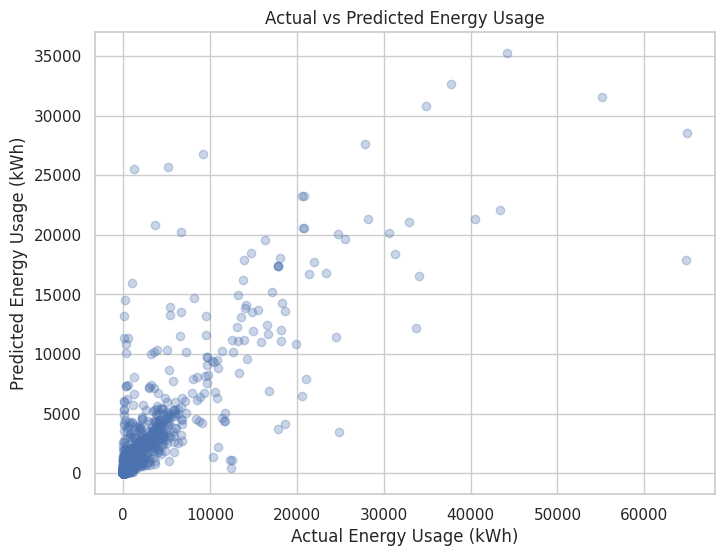

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    results["Actual_Energy_kWh"],
    results["Predicted_Energy_kWh"],
    alpha=0.3
)

plt.xlabel("Actual Energy Usage (kWh)")
plt.ylabel("Predicted Energy Usage (kWh)")
plt.title("Actual vs Predicted Energy Usage")

plt.show()

In [ ]:
# Show the 20 jobs with the largest prediction errors

worst_predictions = results.sort_values(
    by="Absolute_Error",
    ascending=False
).head(20)

worst_predictions

,Actual_Energy_kWh,Predicted_Energy_kWh,Absolute_Error
66670,64744.278292,17926.758688,46817.519603
88937,64892.639766,28577.178309,36315.461457
66717,1193.222910,25523.409792,24330.186882
60869,55179.313805,31527.319444,23651.994361
138467,33716.445006,12209.069682,21507.375324
42789,24845.429519,3453.277447,21392.152072
148297,43435.333800,22119.973243,21315.360557
148484,5189.843400,25694.435314,20504.591914
36729,40473.685695,21335.271920,19138.413775
61740,9168.339452,26811.374474,17643.035022


In [ ]:
# Summary of prediction errors

print("Median Absolute Error:",
      results["Absolute_Error"].median())

print("90th Percentile Absolute Error:",
      results["Absolute_Error"].quantile(0.90))

print("Maximum Absolute Error:",
      results["Absolute_Error"].max())

Median Absolute Error: 0.32360393832609813
90th Percentile Absolute Error: 21.592504786671316
Maximum Absolute Error: 46817.51960339776


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Transform the target
y_train_log = np.log1p(y_train)

# Build the model
log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
log_model.fit(X_train, y_train_log)

print("Log-transformed model training completed!")

Log-transformed model training completed!


In [ ]:
# Predict log energy
y_pred_log = log_model.predict(X_test)

# Convert predictions back to original kWh scale
y_pred_log_kwh = np.expm1(y_pred_log)

# Ensure predictions are not negative
y_pred_log_kwh = np.maximum(y_pred_log_kwh, 0)

# Evaluate
mae_log = mean_absolute_error(y_test, y_pred_log_kwh)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log_kwh))
r2_log = r2_score(y_test, y_pred_log_kwh)

print("Log-Transformed Model Results")
print("-----------------------------")
print(f"MAE:  {mae_log:.4f} kWh")
print(f"RMSE: {rmse_log:.4f} kWh")
print(f"R² Score: {r2_log:.4f}")

Log-Transformed Model Results
-----------------------------
MAE:  61.7385 kWh
RMSE: 812.4983 kWh
R² Score: 0.5952


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest
rf = model.named_steps["regressor"]

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

# Sort by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(15))

                               Feature  Importance
0                  numeric__node_count    0.362144
1                   numeric__wall_time    0.348224
5                numeric__submit_month    0.067816
7                    numeric__hour_sin    0.055142
4            numeric__submit_dayofweek    0.044998
3                 numeric__submit_hour    0.037836
8                    numeric__hour_cos    0.032253
19      categorical__gpu_enabled_False    0.012977
2         numeric__interconnect_exists    0.010807
21    categorical__gpu_enabled_Unknown    0.010699
20       categorical__gpu_enabled_True    0.010341
6                  numeric__is_weekend    0.005958
11     categorical__queue_batch-normal    0.000370
9       categorical__queue_batch-debug    0.000331
16  categorical__queue_extended-normal    0.000053


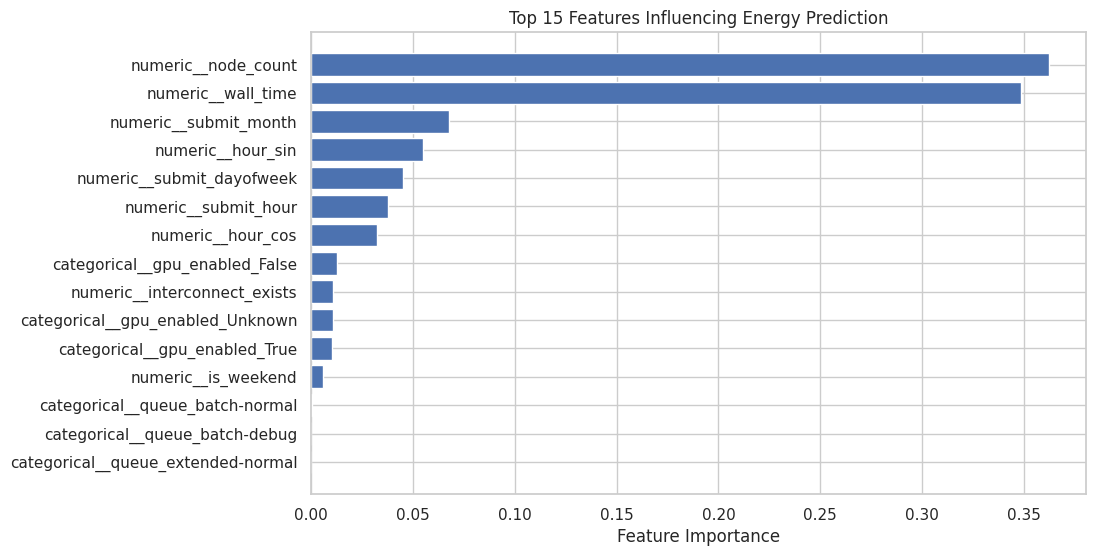

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance.head(15)["Feature"][::-1],
    importance.head(15)["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features Influencing Energy Prediction")

plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict
y_pred_gb = gb_model.predict(X_test)

# Evaluate
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("------------------------")
print(f"MAE:  {mae_gb:.4f} kWh")
print(f"RMSE: {rmse_gb:.4f} kWh")
print(f"R² Score: {r2_gb:.4f}")

Gradient Boosting Results
------------------------
MAE:  87.3119 kWh
RMSE: 732.7780 kWh
R² Score: 0.6707


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest Baseline",
        "Random Forest Log Target",
        "Gradient Boosting"
    ],
    "MAE": [
        mae,
        mae_log,
        mae_gb
    ],
    "RMSE": [
        rmse,
        rmse_log,
        rmse_gb
    ],
    "R2": [
        r2,
        r2_log,
        r2_gb
    ]
})

model_comparison.sort_values(by="MAE")

,Model,MAE,RMSE,R2
0,Random Forest Baseline,54.807143,673.372339,0.721933
1,Random Forest Log Target,61.738508,812.498347,0.595159
2,Gradient Boosting,87.311879,732.777992,0.670706


In [ ]:
# Create a test-results table
evaluation_df = pd.DataFrame({
    "Actual_kWh": y_test,
    "Predicted_kWh": y_pred
})

evaluation_df["Absolute_Error"] = abs(
    evaluation_df["Actual_kWh"] -
    evaluation_df["Predicted_kWh"]
)

# Group jobs by actual energy consumption
bins = [0, 1, 10, 100, 1000, float("inf")]

labels = [
    "0–1 kWh",
    "1–10 kWh",
    "10–100 kWh",
    "100–1,000 kWh",
    "Above 1,000 kWh"
]

evaluation_df["Energy_Range"] = pd.cut(
    evaluation_df["Actual_kWh"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate performance for each group
range_metrics = evaluation_df.groupby(
    "Energy_Range",
    observed=False
).agg(
    Job_Count=("Actual_kWh", "count"),
    Mean_Actual_kWh=("Actual_kWh", "mean"),
    MAE_kWh=("Absolute_Error", "mean")
)

range_metrics

,Job_Count,Mean_Actual_kWh,MAE_kWh
Energy_Range,,,
0–1 kWh,9886,0.312575,0.628554
1–10 kWh,11300,3.682872,2.891444
10–100 kWh,6203,36.222852,22.345719
"100–1,000 kWh",2422,301.306851,151.898027
"Above 1,000 kWh",669,4803.215686,1681.804188


In [ ]:
import numpy as np

error = np.abs(y_test - y_pred)

mape = np.mean(
    np.abs((y_test - y_pred) / y_test)
) * 100

median_error = np.median(error)

within_10_percent = np.mean(
    error <= 0.10 * np.maximum(y_test, 1)
) * 100

within_20_percent = np.mean(
    error <= 0.20 * np.maximum(y_test, 1)
) * 100

print(f"MAPE: {mape:.2f}%")
print(f"Median Absolute Error: {median_error:.4f} kWh")
print(f"Within 10% tolerance: {within_10_percent:.2f}%")
print(f"Within 20% tolerance: {within_20_percent:.2f}%")

MAPE: 130.18%
Median Absolute Error: 0.3236 kWh
Within 10% tolerance: 53.56%
Within 20% tolerance: 66.39%


In [ ]:
import pandas as pd
import numpy as np

# Create a table of actual and predicted energy
results = pd.DataFrame({
    "Actual_kWh": y_test,
    "Predicted_kWh": model.predict(X_test)
})

# Calculate absolute error
results["Absolute_Error"] = (
    results["Actual_kWh"] - results["Predicted_kWh"]
).abs()

# Group jobs by actual energy consumption
results["Energy_Group"] = pd.cut(
    results["Actual_kWh"],
    bins=[-np.inf, 1, 10, 100, 1000, np.inf],
    labels=["0–1 kWh", "1–10 kWh", "10–100 kWh",
            "100–1000 kWh", "Above 1000 kWh"]
)

# Summarize model performance for each group
error_summary = results.groupby(
    "Energy_Group", observed=False
).agg(
    Job_Count=("Actual_kWh", "count"),
    Average_Actual_kWh=("Actual_kWh", "mean"),
    Average_Error_kWh=("Absolute_Error", "mean")
).round(2)

error_summary

,Job_Count,Average_Actual_kWh,Average_Error_kWh
Energy_Group,,,
0–1 kWh,9886,0.31,0.63
1–10 kWh,11300,3.68,2.89
10–100 kWh,6203,36.22,22.35
100–1000 kWh,2422,301.31,151.90
Above 1000 kWh,669,4803.22,1681.80


In [ ]:
worst_predictions = results.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

worst_predictions

,Actual_kWh,Predicted_kWh,Absolute_Error,Energy_Group
66670,64744.278292,17926.758688,46817.519603,Above 1000 kWh
88937,64892.639766,28577.178309,36315.461457,Above 1000 kWh
66717,1193.222910,25523.409792,24330.186882,Above 1000 kWh
60869,55179.313805,31527.319444,23651.994361,Above 1000 kWh
138467,33716.445006,12209.069682,21507.375324,Above 1000 kWh
42789,24845.429519,3453.277447,21392.152072,Above 1000 kWh
148297,43435.333800,22119.973243,21315.360557,Above 1000 kWh
148484,5189.843400,25694.435314,20504.591914,Above 1000 kWh
36729,40473.685695,21335.271920,19138.413775,Above 1000 kWh
61740,9168.339452,26811.374474,17643.035022,Above 1000 kWh


In [ ]:
# Step 1: Check data types
print("Data types:")
print(df[["wall_time", "run_time"]].dtypes)

# Step 2: Check statistical summary
print("\nTime statistics:")
display(
    df[["wall_time", "run_time"]].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

# Step 3: Inspect sample records
print("\nSample records:")
display(
    df[[
        "node_count",
        "wall_time",
        "run_time",
        "mean_power",
        "energy_kwh"
    ]].sample(10, random_state=42)
)

Data types:
wall_time    int64
run_time     int64
dtype: object

Time statistics:


,wall_time,run_time
count,152400.000000,152400.000000
mean,99.568504,4022.559298
std,132.026900,6115.907768
min,1.000000,70.000000
50%,119.000000,2764.000000
90%,120.000000,7217.000000
95%,120.000000,7226.000000
99%,720.000000,24702.060000
max,1440.000000,86429.000000



Sample records:


,node_count,wall_time,run_time,mean_power,energy_kwh
68956,8,120,7203,6569.0,13.143474
119474,1,120,1213,548.0,0.184646
70950,1,10,624,882.0,0.152880
80892,1,5,290,556.0,0.044789
151054,3,120,1437,2820.0,1.125650
55532,1,119,1796,2029.0,1.012246
119166,1,90,5415,845.0,1.271021
39257,1,120,7204,652.0,1.304724
140166,4,30,1804,6586.0,3.300318
67935,64,120,268,59267.0,4.412099


In [ ]:
# Compare wall_time with run_time
df[["wall_time", "run_time"]].sample(20, random_state=42)

,wall_time,run_time
68956,120,7203
119474,120,1213
70950,10,624
80892,5,290
151054,120,1437
55532,119,1796
119166,90,5415
39257,120,7204
140166,30,1804
67935,120,268


In [ ]:
# Compare run_time with wall_time converted to seconds
df["wall_time_seconds"] = df["wall_time"] * 60

# How often did jobs run longer than their requested wall time?
longer_than_wall = (
    df["run_time"] > df["wall_time_seconds"]
).mean() * 100

print(
    f"Jobs running longer than requested wall time: "
    f"{longer_than_wall:.2f}%"
)

# Check the ratio for a few records
df["runtime_to_walltime_ratio"] = (
    df["run_time"] / df["wall_time_seconds"]
)

display(
    df[["wall_time", "run_time", "runtime_to_walltime_ratio"]]
    .sample(10, random_state=42)
)

Jobs running longer than requested wall time: 30.85%


,wall_time,run_time,runtime_to_walltime_ratio
68956,120,7203,1.000417
119474,120,1213,0.168472
70950,10,624,1.040000
80892,5,290,0.966667
151054,120,1437,0.199583
55532,119,1796,0.251541
119166,90,5415,1.002778
39257,120,7204,1.000556
140166,30,1804,1.002222
67935,120,268,0.037222


In [ ]:
# Summarize runtime-to-requested-time ratio
df["runtime_to_walltime_ratio"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

,runtime_to_walltime_ratio
count,152400.000000
mean,0.657509
std,0.346772
min,0.000822
10%,0.120278
25%,0.326667
50%,0.753333
75%,1.001111
90%,1.003889
95%,1.007986


In [ ]:
# Create requested computing capacity in node-hours
df["requested_node_hours"] = (
    df["node_count"] * df["wall_time"] / 60
)

# Inspect the feature
display(
    df[[
        "node_count",
        "wall_time",
        "requested_node_hours"
    ]].head(10)
)

,node_count,wall_time,requested_node_hours
0,60,105,105.000000
1,16,30,8.000000
2,12,60,12.000000
3,2,120,4.000000
4,2048,25,853.333333
5,48,120,96.000000
6,2,120,4.000000
7,3,120,6.000000
8,1,120,2.000000
9,2,120,4.000000


In [ ]:
# Use feature_columns (which is defined in your notebook) instead of the undefined 'features' variable
new_features = feature_columns + ["requested_node_hours"]

X_new = df[new_features]

print("New feature count:", len(new_features))
print("New X shape:", X_new.shape)

New feature count: 13
New X shape: (152400, 13)


In [ ]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Split using the same rows as our original model
X_new_train = X_new.loc[X_train.index]
X_new_test = X_new.loc[X_test.index]

# Create a new model with the same settings
new_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the new model
new_model.fit(X_new_train, y_train)

# Predict on the same test data
new_predictions = new_model.predict(X_new_test)

# Evaluate
new_mae = mean_absolute_error(y_test, new_predictions)
new_rmse = mean_squared_error(y_test, new_predictions) ** 0.5
new_r2 = r2_score(y_test, new_predictions)

print("New Model MAE:", round(new_mae, 2))
print("New Model RMSE:", round(new_rmse, 2))
print("New Model R²:", round(new_r2, 4))

New Model MAE: 55.64
New Model RMSE: 669.65
New Model R²: 0.725


In [ ]:
import pandas as pd
import numpy as np

# Corrected 'predictions' to 'y_pred' to fix the NameError
comparison = pd.DataFrame({
    "Actual": y_test,
    "Baseline_Prediction": y_pred,
    "New_Prediction": new_predictions
})

comparison["Baseline_Abs_Error"] = abs(
    comparison["Actual"] - comparison["Baseline_Prediction"]
)

comparison["New_Abs_Error"] = abs(
    comparison["Actual"] - comparison["New_Prediction"]
)

comparison["Energy_Group"] = pd.cut(
    comparison["Actual"],
    bins=[-np.inf, 1, 10, 100, 1000, np.inf],
    labels=["0–1", "1–10", "10–100", "100–1000", ">1000"]
)

group_comparison = comparison.groupby(
    "Energy_Group", observed=False
).agg(
    Job_Count=("Actual", "count"),
    Baseline_MAE=("Baseline_Abs_Error", "mean"),
    New_MAE=("New_Abs_Error", "mean")
)

group_comparison["MAE_Change"] = (
    group_comparison["New_MAE"] - group_comparison["Baseline_MAE"]
)

group_comparison

,Job_Count,Baseline_MAE,New_MAE,MAE_Change
Energy_Group,,,,
0–1,9886,0.628554,0.623348,-0.005206
1–10,11300,2.891444,2.909987,0.018543
10–100,6203,22.345719,22.415843,0.070125
100–1000,2422,151.898027,155.523230,3.625203
>1000,669,1681.804188,1705.877357,24.073168


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Corrected parameter prefixes from 'model__' to 'regressor__' to match the step name in the pipeline
param_grid = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [None, 10, 20, 30],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": ["sqrt", 0.7, 1.0]
}

rf_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)''

print("Best Parameters:")

print(rf_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-rf_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


KeyboardInterrupt: 

In [ ]:
best_params = {
    'regressor__n_estimators': 300,
    'regressor__max_depth': 30,
    'regressor__min_samples_split': 5,
    'regressor__min_samples_leaf': 1,
    'regressor__max_features': 1.0
}

In [ ]:
print(type(X_train))
print(type(X_test))
print(type(y_train))
print(type(y_test))
print(type(preprocessor))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
<class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

tuned_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=300,
        max_depth=30,
        min_samples_split=5,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

tuned_model.fit(X_train, y_train)

print("Tuned model training completed!")

Tuned model training completed!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tuned_predictions = tuned_model.predict(X_test)

print("Tuned Model MAE:", mean_absolute_error(y_test, tuned_predictions))
print("Tuned Model RMSE:", np.sqrt(mean_squared_error(y_test, tuned_predictions)))
print("Tuned Model R2:", r2_score(y_test, tuned_predictions))

Tuned Model MAE: 56.61241886822416
Tuned Model RMSE: 691.768187656049
Tuned Model R2: 0.7065319701794821


In [ ]:
import joblib

model_path = '/content/drive/MyDrive/DSA COURSE/Main Projecct/tuned_random_forest.joblib'

joblib.dump(tuned_model, model_path)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
%whos

Variable                    Type                     Data/Info
--------------------------------------------------------------
ColumnTransformer           ABCMeta                  <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
GradientBoostingRegressor   ABCMeta                  <class 'sklearn.ensemble.<...>adientBoostingRegressor'>
OneHotEncoder               type                     <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                    ABCMeta                  <class 'sklearn.pipeline.Pipeline'>
RandomForestRegressor       ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
RandomizedSearchCV          ABCMeta                  <class 'sklearn.model_sel<...>arch.RandomizedSearchCV'>
SimpleImputer               type                     <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler              type                     <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                           DataF

In [ ]:
import pandas as pd
import numpy as np

residual_df = pd.DataFrame({
    'Actual_kWh': y_test,
    'Predicted_kWh': y_pred
})

residual_df['Error'] = (
    residual_df['Actual_kWh'] - residual_df['Predicted_kWh']
)

residual_df['Absolute_Error'] = residual_df['Error'].abs()

print("Residual Analysis")
print("-----------------")
print("Average Error:", residual_df['Error'].mean())
print("Average Absolute Error:", residual_df['Absolute_Error'].mean())
print("Largest Error:", residual_df['Absolute_Error'].max())

print("\nLargest 10 Prediction Errors:")
display(
    residual_df.sort_values(
        'Absolute_Error', ascending=False
    ).head(10)
)

Residual Analysis
-----------------
Average Error: 5.111358015776094
Average Absolute Error: 54.80714333792058
Largest Error: 46817.51960339776

Largest 10 Prediction Errors:


,Actual_kWh,Predicted_kWh,Error,Absolute_Error
66670,64744.278292,17926.758688,46817.519603,46817.519603
88937,64892.639766,28577.178309,36315.461457,36315.461457
66717,1193.222910,25523.409792,-24330.186882,24330.186882
60869,55179.313805,31527.319444,23651.994361,23651.994361
138467,33716.445006,12209.069682,21507.375324,21507.375324
42789,24845.429519,3453.277447,21392.152072,21392.152072
148297,43435.333800,22119.973243,21315.360557,21315.360557
148484,5189.843400,25694.435314,-20504.591914,20504.591914
36729,40473.685695,21335.271920,19138.413775,19138.413775
61740,9168.339452,26811.374474,-17643.035022,17643.035022


In [ ]:
# Get the 10 jobs with the largest prediction errors
worst_indices = residual_df.nlargest(
    10, 'Absolute_Error'
).index

# Inspect their model input features
worst_job_features = X_test.loc[worst_indices].copy()

# Add actual and predicted energy
worst_job_features['Actual_kWh'] = y_test.loc[worst_indices]
worst_job_features['Predicted_kWh'] = y_pred[
    X_test.index.get_indexer(worst_indices)
]

worst_job_features['Absolute_Error'] = (
    worst_job_features['Actual_kWh'] -
    worst_job_features['Predicted_kWh']
).abs()

display(worst_job_features)

,node_count,wall_time,queue,job_mode,gpu_enabled,interconnect_exists,submit_hour,submit_dayofweek,submit_month,is_weekend,hour_sin,hour_cos,Actual_kWh,Predicted_kWh,Absolute_Error
66670,2460,715,batch-normal,batch,True,False,22,2,11,0,-0.500000,0.866025,64744.278292,17926.758688,46817.519603
88937,2460,715,batch-normal,batch,True,False,17,3,2,0,-0.965926,-0.258819,64892.639766,28577.178309,36315.461457
66717,8192,720,batch-normal,batch,False,False,22,3,11,0,-0.500000,0.866025,1193.222910,25523.409792,24330.186882
60869,6144,720,batch-normal,batch,Unknown,False,15,0,9,0,-0.707107,-0.707107,55179.313805,31527.319444,23651.994361
138467,2048,720,batch-normal,batch,True,True,21,4,10,0,-0.707107,0.707107,33716.445006,12209.069682,21507.375324
42789,6000,180,batch-normal,batch,Unknown,False,16,4,6,0,-0.866025,-0.500000,24845.429519,3453.277447,21392.152072
148297,4608,360,batch-normal,batch,True,True,0,2,12,0,0.000000,1.000000,43435.333800,22119.973243,21315.360557
148484,1950,720,batch-normal,batch,True,True,21,3,12,0,-0.707107,0.707107,5189.843400,25694.435314,20504.591914
36729,2268,720,batch-normal,batch,Unknown,False,22,3,5,0,-0.500000,0.866025,40473.685695,21335.271920,19138.413775
61740,6144,720,batch-normal,batch,Unknown,False,10,2,10,0,0.500000,-0.866025,9168.339452,26811.374474,17643.035022


In [ ]:
# Inspect original dataset records for the worst jobs

columns_to_check = [
    'node_count',
    'wall_time',
    'run_time',
    'mean_power',
    'peak_power',
    'energy_kwh',
    'completion_state',
    'gpu_enabled',
    'interconnect_exists'
]

available_columns = [
    col for col in columns_to_check if col in df.columns
]

display(
    df.loc[worst_indices, available_columns]
)

,node_count,wall_time,run_time,mean_power,peak_power,energy_kwh,completion_state,gpu_enabled,interconnect_exists
66670,2460,715,42925,5429922.0,5550677.0,64744.278292,TIMEOUT,True,False
88937,2460,715,40762,5731159.0,5832186.0,64892.639766,COMPLETED,True,False
66717,8192,720,946,4540806.0,5259570.0,1193.222910,COMPLETED,False,False
60869,6144,720,43218,4596361.0,10079684.0,55179.313805,TIMEOUT,NaN,False
138467,2048,720,36590,3317278.0,3569483.0,33716.445006,COMPLETED,True,True
42789,6000,180,8087,11060164.0,11927772.0,24845.429519,COMPLETED,NaN,False
148297,4608,360,20871,7492080.0,9489245.0,43435.333800,COMPLETED,True,True
148484,1950,720,7758,2408280.0,2438245.0,5189.843400,CANCELLED,True,True
36729,2268,720,43202,3372651.0,4056243.0,40473.685695,TIMEOUT,NaN,False
61740,6144,720,9982,3306554.0,3725022.0,9168.339452,CANCELLED,NaN,False


In [ ]:
# Create a separate dataset containing completed jobs only

df_completed = df[
    df['completion_state'] == 'COMPLETED'
].copy()

print("Original dataset:", df.shape)
print("Completed jobs dataset:", df_completed.shape)

print("\nCompletion status:")
print(df_completed['completion_state'].value_counts())

Original dataset: (152400, 38)
Completed jobs dataset: (93795, 38)

Completion status:
completion_state
COMPLETED    93795
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Prepare features and target
X_completed = df_completed[feature_columns].copy()
y_completed = df_completed['energy_kwh'].copy()

# 2. Split the completed jobs
X_comp_train, X_comp_test, y_comp_train, y_comp_test = train_test_split(
    X_completed,
    y_completed,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_comp_train.shape)
print("Testing records:", X_comp_test.shape)

# 3. Create a fresh copy of the original model pipeline
completed_model = clone(model)

# 4. Train
completed_model.fit(X_comp_train, y_comp_train)

# 5. Predict
completed_predictions = completed_model.predict(X_comp_test)

# 6. Evaluate
completed_mae = mean_absolute_error(
    y_comp_test, completed_predictions
)
completed_rmse = np.sqrt(mean_squared_error(
    y_comp_test, completed_predictions
))
completed_r2 = r2_score(
    y_comp_test, completed_predictions
)

print("\nCOMPLETED JOBS MODEL RESULTS")
print("MAE:", completed_mae)
print("RMSE:", completed_rmse)
print("R2:", completed_r2)

Training records: (75036, 12)
Testing records: (18759, 12)

COMPLETED JOBS MODEL RESULTS
MAE: 46.813325718458124
RMSE: 701.5678368077641
R2: 0.5467434712771961


In [ ]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Keep the completed-job test records aside
test_indices = X_comp_test.index

# Train an all-jobs model, excluding those same test records
X_all_train = df.loc[
    ~df.index.isin(test_indices), feature_columns
]
y_all_train = df.loc[
    ~df.index.isin(test_indices), 'energy_kwh'
]

# Train the all-jobs model
all_jobs_model = clone(model)
all_jobs_model.fit(X_all_train, y_all_train)

# Predict on the SAME completed-job test records
all_jobs_predictions = all_jobs_model.predict(X_comp_test)

# Evaluate both models on identical test records
comparison_results = pd.DataFrame({
    'Model': ['All Jobs', 'Completed Jobs Only'],
    'MAE': [
        mean_absolute_error(y_comp_test, all_jobs_predictions),
        mean_absolute_error(y_comp_test, completed_predictions)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_comp_test, all_jobs_predictions)),
        np.sqrt(mean_squared_error(y_comp_test, completed_predictions))
    ],
    'R2': [
        r2_score(y_comp_test, all_jobs_predictions),
        r2_score(y_comp_test, completed_predictions)
    ]
})

display(comparison_results.round(4))

,Model,MAE,RMSE,R2
0,All Jobs,54.3340,696.5797,0.5532
1,Completed Jobs Only,46.8133,701.5678,0.5467


In [ ]:
completed_residuals = pd.DataFrame({
    'Actual': y_comp_test,
    'Predicted': completed_predictions
})

completed_residuals['Error'] = (
    completed_residuals['Actual'] -
    completed_residuals['Predicted']
)

completed_residuals['Absolute_Error'] = (
    completed_residuals['Error'].abs()
)

print("Completed Jobs Residual Analysis")
print("MAE:", completed_residuals['Absolute_Error'].mean())
print("Largest Error:", completed_residuals['Absolute_Error'].max())

display(
    completed_residuals.nlargest(10, 'Absolute_Error')
)

Completed Jobs Residual Analysis
MAE: 46.813325718458124
Largest Error: 57646.214356575554


,Actual,Predicted,Error,Absolute_Error
88937,64892.639766,7246.425410,57646.214357,57646.214357
78048,57928.838005,8071.039214,49857.798791,49857.798791
54295,35352.105528,13380.922980,21971.182548,21971.182548
26727,173.366758,15225.424539,-15052.057781,15052.057781
149499,20444.921135,5661.884284,14783.036851,14783.036851
12846,32883.016444,19639.701281,13243.315163,13243.315163
7027,16693.529792,5248.834143,11444.695649,11444.695649
71860,13887.323778,2750.010595,11137.313183,11137.313183
55547,15463.318129,4898.778579,10564.539550,10564.539550
58931,34638.104595,24766.310661,9871.793934,9871.793934


In [ ]:
feature_audit = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.astype(str).values,
    'missing_pct': (df.isna().mean() * 100).round(2).values,
    'unique_values': df.nunique(dropna=False).values
})

display(feature_audit)

,column,dtype,missing_pct,unique_values
0,job_idx,int64,0.00,152400
1,date_dir,object,0.00,135
2,node_count,int64,0.00,619
3,submit_time,"datetime64[ns, UTC]",0.00,99851
4,start_time,object,0.00,91012
5,end_time,object,0.00,125963
6,wall_time,int64,0.00,177
7,queue_time,float64,0.00,38950
8,run_time,int64,0.00,10130
9,node_hour_usage,float64,0.00,31643


In [ ]:
candidate_columns = [
    'project_prefix',
    'init_priority',
    'node_group',
    'wall_time_group'
]

for col in candidate_columns:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isna().sum())

    if df[col].nunique() <= 50:
        print(df[col].value_counts(dropna=False))
    else:
        print(df[col].describe())


--- project_prefix ---
Unique values: 36
Missing values: 0
project_prefix
VNY    23514
FZN    15398
YIE     9673
LYB     9242
IZB     8336
OHF     8325
TBX     8288
RPM     8041
LDQ     7093
OWM     5529
MPT     4998
TLF     4311
FGQ     4181
MER     4122
ISE     3952
EJP     3525
UVT     3495
AWS     2663
KDR     2566
TYO     2395
AQT     2022
UYS     1990
WQY     1639
GTO     1543
YMH     1409
YNE     1196
ULR      937
ILY      800
AIU      736
WBM      211
WMJ      155
EVP       62
YZG       39
SJH       11
MOS        2
PKB        1
Name: count, dtype: int64

--- init_priority ---
Unique values: 1139
Missing values: 1004
count    1.513960e+05
mean    -4.645252e+05
std      3.908626e+06
min     -4.320000e+07
25%      0.000000e+00
50%      1.728000e+05
75%      1.728000e+05
max      3.084480e+07
Name: init_priority, dtype: float64

--- node_group ---
Unique values: 6
Missing values: 0
node_group
1 Node          55981
2-4 Nodes       29804
5-16 Nodes      25860
17-64 Nodes     20228
6

In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Existing features + new candidate features
improved_features = feature_columns + [
    'node_group',
    'wall_time_group',
    'project_prefix'
]

X_improved = df_completed[improved_features]
y_improved = df_completed['energy_kwh']

# Use exactly the same completed-job split
X_train_new = X_improved.loc[X_comp_train.index]
X_test_new = X_improved.loc[X_comp_test.index]

y_train_new = y_improved.loc[y_comp_train.index]
y_test_new = y_improved.loc[y_comp_test.index]

# Identify numerical and categorical columns
numeric_cols = X_improved.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X_improved.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Preprocessing
preprocessor_new = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
])

# Keep the same model settings for a fair feature comparison
improved_model = Pipeline([
    ('preprocessor', preprocessor_new),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

improved_model.fit(X_train_new, y_train_new)

improved_predictions = improved_model.predict(X_test_new)

print("MAE:", mean_absolute_error(y_test_new, improved_predictions))
print("RMSE:", mean_squared_error(y_test_new, improved_predictions) ** 0.5)
print("R2:", r2_score(y_test_new, improved_predictions))

MAE: 43.600422726920236
RMSE: 700.5285392492964
R2: 0.5480853785320293


In [ ]:
import pandas as pd
import numpy as np

results = pd.DataFrame({
    'Actual': y_test_new,
    'Predicted': improved_predictions
})

results['Absolute_Error'] = (
    results['Actual'] - results['Predicted']
).abs()

bins = [0, 1, 10, 100, 1000, np.inf]
labels = ['0-1', '1-10', '10-100', '100-1000', '>1000']

results['Energy_Range'] = pd.cut(
    results['Actual'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

bucket_results = results.groupby(
    'Energy_Range',
    observed=True
).agg(
    Job_Count=('Actual', 'count'),
    MAE=('Absolute_Error', 'mean')
).round(2)

display(bucket_results)

,Job_Count,MAE
Energy_Range,,
0-1,7303,0.47
1-10,6265,2.78
10-100,3366,24.62
100-1000,1483,159.01
>1000,342,1398.65


In [ ]:
print("Largest prediction errors:")
display(
    results.nlargest(10, 'Absolute_Error')
)

Largest prediction errors:


,Actual,Predicted,Absolute_Error,Energy_Range
88937,64892.639766,7082.167316,57810.472450,>1000
78048,57928.838005,6431.880905,51496.957099,>1000
12846,32883.016444,12260.072089,20622.944356,>1000
23594,28193.119312,12112.255049,16080.864264,>1000
26727,173.366758,15349.243065,15175.876308,100-1000
149499,20444.921135,5815.188507,14629.732628,>1000
7027,16693.529792,4815.679871,11877.849921,>1000
54295,35352.105528,23489.424017,11862.681511,>1000
71860,13887.323778,3688.336540,10198.987238,>1000
24414,84.152366,10265.886666,10181.734300,10-100
